# 6.4 PINN与传统数值方法：正问题、反问题与算子学习

Python **3.12.x**；全部实验代码内嵌于本Notebook，无外部py/m文件依赖。
运行前请将当前目录设为本Notebook所在的提交根目录；三个资源目录随提交包提供，代码不会创建目录。
重启内核后从头执行。所有输出写入已有的相对路径“图片/”“数据/”，同名文件会更新。

前三部分：A.复跑6.1正问题比较；B.沿用6.2的E1—E5及NumPy PINN，与解析最小二乘和差分反演对照；
C.采用6.3提供的同一批输入系数，将DeepONet重写为Python/PyTorch，与同样32个传感器信息的谱/差分方法比较。
FNO只作结构对照，本包没有FNO训练结果。原MATLAB结果为明确标记的“来源数据”，不混入本机计时。

运行前预测：网格方法函数二阶、导数一阶；内点无噪声反演可由最小二乘精确识别，边界观测不含系数信息；
DeepONet只保证对本次测试集的实测结果，是否出现正成本摊销点由同机测量决定，不预设其加速。
人工核验和B/C独立验证不在本Notebook中宣称完成。

In [1]:
import os, sys, json, time, platform, csv
os.environ['OMP_NUM_THREADS']='1'
os.environ['MKL_NUM_THREADS']='1'
os.environ['OPENBLAS_NUM_THREADS']='1'
from pathlib import Path
import numpy as np
import scipy
from scipy.linalg import solve_banded
import matplotlib
import matplotlib.pyplot as plt
import torch
from threadpoolctl import threadpool_limits, threadpool_info
from IPython.display import display, Markdown

THREAD_LIMIT = threadpool_limits(limits=1)
assert sys.version_info[:2] == (3, 12), '必须使用Python 3.12.x内核'
torch.set_num_threads(1)
torch.set_default_dtype(torch.float64)
torch.use_deterministic_algorithms(True)
DEVICE = torch.device('cpu')
DATA, FIG = Path('数据'), Path('图片')
assert DATA.is_dir() and FIG.is_dir(), '请在工作目录运行，并保留随包提供的图片/数据目录'
plt.rcParams.update({'figure.dpi':120, 'axes.grid':True, 'font.size':10})
ENV = dict(python=platform.python_version(), numpy=np.__version__, scipy=scipy.__version__,
           torch=torch.__version__, matplotlib=matplotlib.__version__, platform=platform.platform(),
           processor=platform.processor(), device='CPU', torch_threads=torch.get_num_threads(),
           dtype='float64', source_commit='55ae9bcd10fbabb3dd4a5a8de393bd05899abda2',
           seeds=[0,1,2], date='2026-10-26', run_time=time.strftime('%Y-%m-%d %H:%M:%S %z'))
ENV['threadpools']=[{k:p.get(k) for k in ['internal_api','prefix','num_threads','version']} for p in threadpool_info()]
print(json.dumps(ENV, indent=2, ensure_ascii=False))

def exact(x): return np.sin(np.pi*x)
def exact_d(x): return np.pi*np.cos(np.pi*x)
def forcing(x): return np.pi**2*np.sin(np.pi*x)

def table(rows, cols):
    def fmt(v):
        return f'{v:.6e}' if isinstance(v, (float, np.floating)) else str(v)
    display(Markdown('| '+' | '.join(cols)+' |\n| '+' | '.join(['---']*len(cols))+' |\n'+
                     '\n'.join('| '+' | '.join(fmt(r.get(c,'')) for c in cols)+' |' for r in rows)))

def save_csv(path, rows):
    keys=list(dict.fromkeys(k for row in rows for k in row))
    with open(path,'w',encoding='utf-8-sig',newline='') as fh:
        w=csv.DictWriter(fh,fieldnames=keys); w.writeheader(); w.writerows(rows)

{
  "python": "3.12.14",
  "numpy": "2.2.6",
  "scipy": "1.15.3",
  "torch": "2.6.0+cpu",
  "matplotlib": "3.10.3",
  "platform": "Windows-10-10.0.19045-SP0",
  "processor": "Intel64 Family 6 Model 141 Stepping 1, GenuineIntel",
  "device": "CPU",
  "torch_threads": 1,
  "dtype": "float64",
  "source_commit": "55ae9bcd10fbabb3dd4a5a8de393bd05899abda2",
  "seeds": [
    0,
    1,
    2
  ],
  "date": "2026-10-26",
  "run_time": "2026-10-26 16:20:39 +0800",
  "threadpools": [
    {
      "internal_api": "openblas",
      "prefix": "libscipy_openblas",
      "num_threads": 1,
      "version": "0.3.29"
    },
    {
      "internal_api": "openblas",
      "prefix": "libscipy_openblas",
      "num_threads": 1,
      "version": "0.3.28"
    },
    {
      "internal_api": "openmp",
      "prefix": "libiomp",
      "num_threads": 1,
      "version": null
    },
    {
      "internal_api": "openmp",
      "prefix": "libiomp",
      "num_threads": 1,
      "version": null
    }
  ]
}


## 6.4.1 共同评价协议

网格方法在节点间按分段直线重建；不能把它们的节点误差与PINN的全域误差混为一谈。
主评价采用800等分、每段4点Gauss积分，共3200点。这些点与256个PINN训练中点分离；所有方法使用完全相同的点与权重。

$$
E_0=\sqrt{\frac{\sum_qw_q(v(x_q)-u^*(x_q))^2}{\sum_qw_q u^*(x_q)^2}},\qquad
E_1=\sqrt{\frac{\sum_qw_q(v'(x_q)-u^{*\prime}(x_q))^2}{\sum_qw_q u^{*\prime}(x_q)^2}}.
$$

$E_1$是相对$H^1$**半范数**误差，不是完整$H^1$范数。最大误差是10001点上的采样最大值，不是严格连续上确界。
阈值$10^{-3}$、$10^{-4}$、$10^{-5}$是教学用精度档位，不是工程安全标准。预先固定，不据此反复调参选最好种子。

In [2]:
def quadrature(cells=800, order=4):
    z,w=np.polynomial.legendre.leggauss(order)
    x=(np.arange(cells)[:,None]+(z[None,:]+1)/2)/cells
    weights=np.broadcast_to(w[None,:]/(2*cells), x.shape)
    return x.ravel(), weights.ravel()

XQ,WQ=quadrature()
XD=np.linspace(0,1,10001)
TRAIN_X=(np.arange(256)+0.5)/256
assert np.min(abs(XQ[:,None]-TRAIN_X[None,:]))>1e-12
assert abs(WQ.sum()-1)<1e-14
assert abs(np.dot(WQ,exact(XQ)**2)-0.5)<1e-13

def metrics(value, deriv, xq=XQ, wq=WQ):
    v=value(xq); d=deriv(xq)
    return dict(rel_l2=float(np.sqrt(np.dot(wq,(v-exact(xq))**2)/np.dot(wq,exact(xq)**2))),
                rel_h1_semi=float(np.sqrt(np.dot(wq,(d-exact_d(xq))**2)/np.dot(wq,exact_d(xq)**2))),
                max_sample=float(np.max(abs(value(XD)-exact(XD)))),
                boundary_max=float(np.max(abs(value(np.array([0.,1.]))))))

print('评价点数:',len(XQ),'；训练/主评价最小间距:',np.min(abs(XQ[:,None]-TRAIN_X[None,:])))

评价点数: 3200 ；训练/主评价最小间距: 8.664805253688623e-06


## 6.4.2 有限差分与真正组装的P1有限元

令n表示**区间数**，h=1/n，内部未知量n-1个。
FD矩阵为$h^{-2}\operatorname{tridiag}(-1,2,-1)$，右端为$f(x_i)$。
FEM每单元刚度矩阵为

$$
h^{-1}\begin{pmatrix}1&-1\\-1&1\end{pmatrix}
$$

载荷为 $\int_K f\phi_i$，用4点Gauss积分。
两者均使用三对角带状直接求解，不采用不必要的稠密求解。

计时包含网格、矩阵/载荷组装、线性求解；不含导入、绘图和精确解评价。预热后7批、每批30次，报告每次耗时的批中位数及四分位区间。
重复微小问题仅为降低计时噪声，不意味着有7份独立硬件实验。

In [3]:
def band_solve(diag, off, rhs):
    m=len(rhs); ab=np.zeros((3,m))
    ab[1]=diag; ab[0,1:]=off; ab[2,:-1]=off
    return solve_banded((1,1),ab,rhs,check_finite=True)

def fd(n):
    h=1/n; x=np.linspace(0,1,n+1)
    u=np.zeros(n+1)
    u[1:-1]=band_solve(np.full(n-1,2/h**2),np.full(n-2,-1/h**2),forcing(x[1:-1]))
    return x,u

def fem(n, order=4):
    x=np.linspace(0,1,n+1); h=1/n
    z,w=np.polynomial.legendre.leggauss(order); t=(z+1)/2
    f=forcing(x[:-1,None]+h*t[None,:])
    left=h/2*np.sum(f*(w*(1-t))[None,:],axis=1)
    right=h/2*np.sum(f*(w*t)[None,:],axis=1)
    load=np.zeros(n+1); load[:-1]+=left; load[1:]+=right
    # Assemble local [1,-1;-1,1]/h, including endpoints before Dirichlet elimination.
    diag=np.zeros(n+1); diag[:-1]+=1/h; diag[1:]+=1/h
    off=np.full(n,-1/h); u=np.zeros(n+1)
    u[1:-1]=band_solve(diag[1:-1],off[1:-1],load[1:-1])
    return x,u

def grid_functions(x,u):
    slopes=np.diff(u)/np.diff(x)
    def value(z): return np.interp(z,x,u)
    def deriv(z):
        i=np.clip(np.searchsorted(x,z,side='right')-1,0,len(slopes)-1)
        return slopes[i]
    return value,deriv

def timed_grid(solver,n):
    solver(n)
    times=[]
    for _ in range(7):
        t=time.perf_counter()
        for _ in range(30): solver(n)
        times.append((time.perf_counter()-t)/30)
    return dict(solve_s=float(np.median(times)), time_q25_s=float(np.quantile(times,.25)),
                time_q75_s=float(np.quantile(times,.75)))

grid_rows=[]; solutions={}; checks={}
for name,solver in [('FD',fd),('FEM',fem)]:
    for n in [50,100,200,400,800]:
        x,u=solver(n); value,deriv=grid_functions(x,u)
        row=dict(method=name,n=n,dof=n-1,**metrics(value,deriv),**timed_grid(solver,n),
                 nodal_max=float(np.max(abs(u-exact(x)))))
        if n>50:
            prev=grid_rows[-1]
            row['order_l2']=float(np.log2(prev['rel_l2']/row['rel_l2']))
            row['order_h1']=float(np.log2(prev['rel_h1_semi']/row['rel_h1_semi']))
        grid_rows.append(row); solutions[(name,n)]=(value,deriv)

# Independent analytic identities, not just agreement between two implementations.
n=100; x,u=fd(n); h=1/n
factor=np.pi**2/(4/h**2*np.sin(np.pi*h/2)**2)
checks['fd_discrete_sine_maxdiff']=float(np.max(abs(u-factor*exact(x))))
x,u=fem(100)
checks['fem_nodal_maxdiff']=float(np.max(abs(u-exact(x))))
checks['fem_gauss4_vs8_maxdiff']=float(np.max(abs(u-fem(100,8)[1])))
assert checks['fd_discrete_sine_maxdiff']<1e-10
assert checks['fem_nodal_maxdiff']<1e-10
assert checks['fem_gauss4_vs8_maxdiff']<1e-11
for r in grid_rows:
    if r['n']>50:
        assert 1.95<r['order_l2']<2.05
        assert .95<r['order_h1']<1.05
table(grid_rows,['method','n','rel_l2','rel_h1_semi','nodal_max','solve_s','order_l2'])
print('独立校验:',checks)

| method | n | rel_l2 | rel_h1_semi | nodal_max | solve_s | order_l2 |
| --- | --- | --- | --- | --- | --- | --- |
| FD | 50 | 1.471965e-04 | 1.813978e-02 | 3.290518e-04 | 2.606333e-05 |  |
| FD | 100 | 3.678617e-05 | 9.069221e-03 | 8.225076e-05 | 2.851667e-05 | 2.000508e+00 |
| FD | 200 | 9.195731e-06 | 4.534526e-03 | 2.056193e-05 | 3.366667e-05 | 2.000127e+00 |
| FD | 400 | 2.298882e-06 | 2.267253e-03 | 5.140435e-06 | 3.958333e-05 | 2.000032e+00 |
| FD | 800 | 5.747174e-07 | 1.133625e-03 | 1.285106e-06 | 5.046333e-05 | 2.000008e+00 |
| FEM | 50 | 3.603559e-04 | 1.813680e-02 | 3.885781e-15 | 1.877500e-04 |  |
| FEM | 100 | 9.009481e-05 | 9.068848e-03 | 4.440892e-15 | 1.884400e-04 | 1.999907e+00 |
| FEM | 200 | 2.252407e-05 | 4.534480e-03 | 1.265654e-14 | 2.002300e-04 | 1.999977e+00 |
| FEM | 400 | 5.631039e-06 | 2.267247e-03 | 8.215650e-14 | 2.167867e-04 | 1.999994e+00 |
| FEM | 800 | 1.407761e-06 | 1.133624e-03 | 3.005374e-13 | 2.746867e-04 | 1.999998e+00 |

独立校验: {'fd_discrete_sine_maxdiff': 2.6645352591003757e-15, 'fem_nodal_maxdiff': 4.440892098500626e-15, 'fem_gauss4_vs8_maxdiff': 0.0}


## 6.4.3 PINN：继承6.1的方法，不复制其旧运行数字

网络1-32-32-1、tanh，共1153参数；内部配点256个等距中点。软边界为$u_\theta=N_\theta$、$L=L_r+L_b$；
硬边界为$u_\theta=x(1-x)N_\theta$、仅优化$L_r$。两者都输出$L_b$供核查。
Adam学习率$10^{-3}$，3000次更新，然后一次LBFGS调用，最多100内部迭代，`history_size=30`，`strong_wolfe`线搜索；
显式设置PyTorch默认tol_grad=$10^{-7}$、tol_change=$10^{-9}$。早停可能导致不足100次，必须记录真实次数与闭包调用数。
种子0/1/2全部保留。采用默认Linear初始化，与6.1一致。

耗时包含模型与优化器构建、全部训练及稀疏训练日志，不包含评价精确解、绘图、导入/一次性优化器预热。
CPU单线程使同机比较更清楚，但不代表GPU加速表现。真实解只用于训练完成后的评价。

In [4]:
class PINN(torch.nn.Module):
    def __init__(self,hard=False):
        super().__init__(); self.hard=hard
        self.net=torch.nn.Sequential(torch.nn.Linear(1,32),torch.nn.Tanh(),
            torch.nn.Linear(32,32),torch.nn.Tanh(),torch.nn.Linear(32,1))
    def forward(self,x):
        y=self.net(x)
        return x*(1-x)*y if self.hard else y

XT=torch.tensor(TRAIN_X[:,None],device=DEVICE)
XB=torch.tensor([[0.],[1.]],device=DEVICE)

def losses(model):
    x=XT.detach().clone().requires_grad_(True)
    y=model(x)
    dy=torch.autograd.grad(y,x,torch.ones_like(y),create_graph=True)[0]
    ddy=torch.autograd.grad(dy,x,torch.ones_like(dy),create_graph=True)[0]
    lr=((-ddy-torch.pi**2*torch.sin(torch.pi*x))**2).mean()
    lb=(model(XB)**2).mean()
    return (lr if model.hard else lr+lb),lr,lb

def network_functions(model):
    def value(z):
        with torch.no_grad(): return model(torch.tensor(np.asarray(z).reshape(-1,1))).numpy().ravel()
    def deriv(z):
        x=torch.tensor(np.asarray(z).reshape(-1,1),requires_grad=True)
        y=model(x)
        return torch.autograd.grad(y,x,torch.ones_like(y))[0].detach().numpy().ravel()
    return value,deriv

def independent_residual(model):
    x=torch.tensor(XQ[:,None],requires_grad=True); y=model(x)
    dy=torch.autograd.grad(y,x,torch.ones_like(y),create_graph=True)[0]
    ddy=torch.autograd.grad(dy,x,torch.ones_like(dy))[0].detach().numpy().ravel()
    return float(np.sqrt(np.dot(WQ,(-ddy-forcing(XQ))**2)))

# Exclude one-time optimizer startup from the six timed runs.
warm=torch.nn.Parameter(torch.ones(1)); opt=torch.optim.Adam([warm])
opt.zero_grad(); (warm**2).sum().backward(); opt.step()
del warm,opt

def train_pinn(seed,hard):
    torch.manual_seed(seed); t0=time.perf_counter()
    model=PINN(hard).to(DEVICE)
    adam=torch.optim.Adam(model.parameters(),lr=1e-3)
    history=[]
    for step in range(3001):
        adam.zero_grad(set_to_none=True); loss,lr,lb=losses(model)
        if step%100==0:
            history.append(dict(phase='Adam',step=step,loss=float(loss.detach()),
                                residual_loss=float(lr.detach()),boundary_loss=float(lb.detach())))
        if step==3000: break
        loss.backward(); adam.step()
    adam_s=time.perf_counter()-t0
    lbfgs=torch.optim.LBFGS(model.parameters(),lr=1,max_iter=100,history_size=30,
                           tolerance_grad=1e-7,tolerance_change=1e-9,line_search_fn='strong_wolfe')
    calls=0
    def closure():
        nonlocal calls
        calls+=1; lbfgs.zero_grad(set_to_none=True)
        loss,_,_=losses(model); loss.backward(); return loss
    lbfgs.step(closure)
    loss,lr,lb=losses(model)
    history.append(dict(phase='LBFGS-final',step=3000,loss=float(loss.detach()),
                        residual_loss=float(lr.detach()),boundary_loss=float(lb.detach())))
    elapsed=time.perf_counter()-t0
    state=lbfgs.state[next(iter(model.parameters()))]
    value,deriv=network_functions(model)
    row=dict(method='PINN-hard' if hard else 'PINN-soft',seed=seed,dof=sum(p.numel() for p in model.parameters()),
             **metrics(value,deriv),solve_s=elapsed,adam_s=adam_s,
             train_residual_mse=float(lr.detach()),train_boundary_mse=float(lb.detach()),
             train_total=float(loss.detach()),test_residual_l2=independent_residual(model),
             lbfgs_iterations=int(state['n_iter']),lbfgs_closures=calls)
    assert row['dof']==1153 and np.isfinite(row['rel_l2'])
    if hard: assert row['boundary_max']==0
    return model,row,history

models={}; pinn_rows=[]; histories={}
for hard in [False,True]:
    for seed in [0,1,2]:
        model,row,hist=train_pinn(seed,hard)
        models[(row['method'],seed)]=model
        pinn_rows.append(row); histories[f'{row["method"]}-{seed}']=hist
        print(f'{row["method"]}, seed={seed}: L2={row["rel_l2"]:.4e}, H1semi={row["rel_h1_semi"]:.4e}, '
              f'boundary={row["boundary_max"]:.3e}, time={row["solve_s"]:.3f}s, '
              f'LBFGS iterations={row["lbfgs_iterations"]}, closures={row["lbfgs_closures"]}',flush=True)
table(pinn_rows,['method','seed','rel_l2','rel_h1_semi','boundary_max','test_residual_l2','solve_s'])

PINN-soft, seed=0: L2=2.2445e-04, H1semi=6.1675e-05, boundary=1.564e-04, time=4.937s, LBFGS iterations=100, closures=119


PINN-soft, seed=1: L2=1.0762e-04, H1semi=1.8517e-05, boundary=7.609e-05, time=4.966s, LBFGS iterations=100, closures=113


PINN-soft, seed=2: L2=1.0684e-05, H1semi=6.9563e-05, boundary=4.218e-06, time=4.765s, LBFGS iterations=39, closures=41


PINN-hard, seed=0: L2=2.9485e-06, H1semi=1.6626e-05, boundary=0.000e+00, time=5.701s, LBFGS iterations=36, closures=40


PINN-hard, seed=1: L2=2.5249e-06, H1semi=8.2376e-06, boundary=0.000e+00, time=5.798s, LBFGS iterations=67, closures=74


PINN-hard, seed=2: L2=5.4295e-06, H1semi=3.5475e-05, boundary=0.000e+00, time=5.737s, LBFGS iterations=59, closures=67


| method | seed | rel_l2 | rel_h1_semi | boundary_max | test_residual_l2 | solve_s |
| --- | --- | --- | --- | --- | --- | --- |
| PINN-soft | 0 | 2.244509e-04 | 6.167505e-05 | 1.564475e-04 | 3.467006e-03 | 4.936952e+00 |
| PINN-soft | 1 | 1.076152e-04 | 1.851745e-05 | 7.609206e-05 | 1.233891e-03 | 4.966344e+00 |
| PINN-soft | 2 | 1.068378e-05 | 6.956337e-05 | 4.218488e-06 | 4.165341e-03 | 4.764623e+00 |
| PINN-hard | 0 | 2.948492e-06 | 1.662623e-05 | 0.000000e+00 | 8.909868e-04 | 5.701085e+00 |
| PINN-hard | 1 | 2.524941e-06 | 8.237646e-06 | 0.000000e+00 | 3.802702e-04 | 5.797943e+00 |
| PINN-hard | 2 | 5.429532e-06 | 3.547516e-05 | 0.000000e+00 | 1.993033e-03 | 5.737410e+00 |

## 6.4.4 数值自检、同精度比较与统计

评价积分加密到1600段，检查结论是否依赖评价分辨率；这不是数学上的严格积分误差证书。
同时核查6.1的仿射反例：$v=u^*+3x+2$，残差为零，边界为2和5，连续相对$L^2$误差为$\sqrt{26}$。
PINN误差的连续残差上界：

$$
\|v-u^*\|_2\le\sqrt{(a^2+ab+b^2)/3}+\|{-v''-f}\|_2/\pi^2.
$$

这里使用数值积分检查一致性，不把有限点残差当作严格连续误差证书。边界项是**上界的一部分**，不是由此自动得到的误差下界。

In [5]:
XQ2,WQ2=quadrature(1600)
quad_checks=[]
for r in grid_rows:
    fun=solutions[(r['method'],r['n'])]
    refined=metrics(*fun,xq=XQ2,wq=WQ2)
    quad_checks.append(dict(method=r['method'],case=r['n'],delta_l2=abs(refined['rel_l2']-r['rel_l2']),
                            delta_h1=abs(refined['rel_h1_semi']-r['rel_h1_semi'])))
for r in pinn_rows:
    model=models[(r['method'],r['seed'])]; fun=network_functions(model)
    refined=metrics(*fun,xq=XQ2,wq=WQ2)
    quad_checks.append(dict(method=r['method'],case=r['seed'],delta_l2=abs(refined['rel_l2']-r['rel_l2']),
                            delta_h1=abs(refined['rel_h1_semi']-r['rel_h1_semi'])))
    a,b=fun[0](np.array([0.,1.]))
    bound=np.sqrt((a*a+a*b+b*b)/3)+r['test_residual_l2']/np.pi**2
    r['estimated_abs_l2_bound']=float(bound)
    r['bound_check']=bool(r['rel_l2']/np.sqrt(2)<=bound+1e-10)
    assert r['bound_check']
checks['max_quadrature_delta_l2']=max(r['delta_l2'] for r in quad_checks)
checks['max_quadrature_delta_h1']=max(r['delta_h1'] for r in quad_checks)
checks['affine_counterexample_rel_l2']=float(np.sqrt(np.dot(WQ,(3*XQ+2)**2)/.5))
assert abs(checks['affine_counterexample_rel_l2']-np.sqrt(26))<1e-12
assert checks['max_quadrature_delta_l2']<1e-8
assert checks['max_quadrature_delta_h1']<1e-8
summary=[]
for method in ['PINN-soft','PINN-hard']:
    rows=[r for r in pinn_rows if r['method']==method]
    summary.append(dict(method=method,seeds=len(rows),l2_min=min(r['rel_l2'] for r in rows),
                        l2_median=float(np.median([r['rel_l2'] for r in rows])),l2_max=max(r['rel_l2'] for r in rows),
                        time_median_s=float(np.median([r['solve_s'] for r in rows]))))
thresholds=[]
for tol in [1e-3,1e-4,1e-5]:
    for method in ['FD','FEM','PINN-soft','PINN-hard']:
        rows=[r for r in grid_rows+pinn_rows if r['method']==method]
        passed=[r for r in rows if r['rel_l2']<=tol]
        thresholds.append(dict(tolerance=tol,method=method,passed=len(passed),tested=len(rows),
                               min_observed_s=min((r['solve_s'] for r in passed),default=None)))
table(summary,['method','seeds','l2_min','l2_median','l2_max','time_median_s'])
table(thresholds,['tolerance','method','passed','tested','min_observed_s'])
print('全部自检通过:',json.dumps(checks,indent=2,ensure_ascii=False))
print('阈值表仅为已测试配置的观察值；网格的通过数是不同网格，PINN的通过数是不同种子，不能当成同一统计含义。')

| method | seeds | l2_min | l2_median | l2_max | time_median_s |
| --- | --- | --- | --- | --- | --- |
| PINN-soft | 3 | 1.068378e-05 | 1.076152e-04 | 2.244509e-04 | 4.936952e+00 |
| PINN-hard | 3 | 2.524941e-06 | 2.948492e-06 | 5.429532e-06 | 5.737410e+00 |

| tolerance | method | passed | tested | min_observed_s |
| --- | --- | --- | --- | --- |
| 1.000000e-03 | FD | 5 | 5 | 2.606333e-05 |
| 1.000000e-03 | FEM | 5 | 5 | 1.877500e-04 |
| 1.000000e-03 | PINN-soft | 3 | 3 | 4.764623e+00 |
| 1.000000e-03 | PINN-hard | 3 | 3 | 5.701085e+00 |
| 1.000000e-04 | FD | 4 | 5 | 2.851667e-05 |
| 1.000000e-04 | FEM | 4 | 5 | 1.884400e-04 |
| 1.000000e-04 | PINN-soft | 1 | 3 | 4.764623e+00 |
| 1.000000e-04 | PINN-hard | 3 | 3 | 5.701085e+00 |
| 1.000000e-05 | FD | 3 | 5 | 3.366667e-05 |
| 1.000000e-05 | FEM | 2 | 5 | 2.167867e-04 |
| 1.000000e-05 | PINN-soft | 0 | 3 | None |
| 1.000000e-05 | PINN-hard | 3 | 3 | 5.701085e+00 |

全部自检通过: {
  "fd_discrete_sine_maxdiff": 2.6645352591003757e-15,
  "fem_nodal_maxdiff": 4.440892098500626e-15,
  "fem_gauss4_vs8_maxdiff": 0.0,
  "max_quadrature_delta_l2": 3.415236843329339e-18,
  "max_quadrature_delta_h1": 2.949029909160572e-17,
  "affine_counterexample_rel_l2": 5.0990195135927845
}
阈值表仅为已测试配置的观察值；网格的通过数是不同网格，PINN的通过数是不同种子，不能当成同一统计含义。


## 6.4.5 图表与可迁移输出

图中seed=0在运行前固定为代表曲线，不选择最好一次；全部种子仍在表中。
FD/FEM展示n=50，让节点间误差可见。耗时-误差图使用对数坐标，点集不是各方法的最优性能边界。

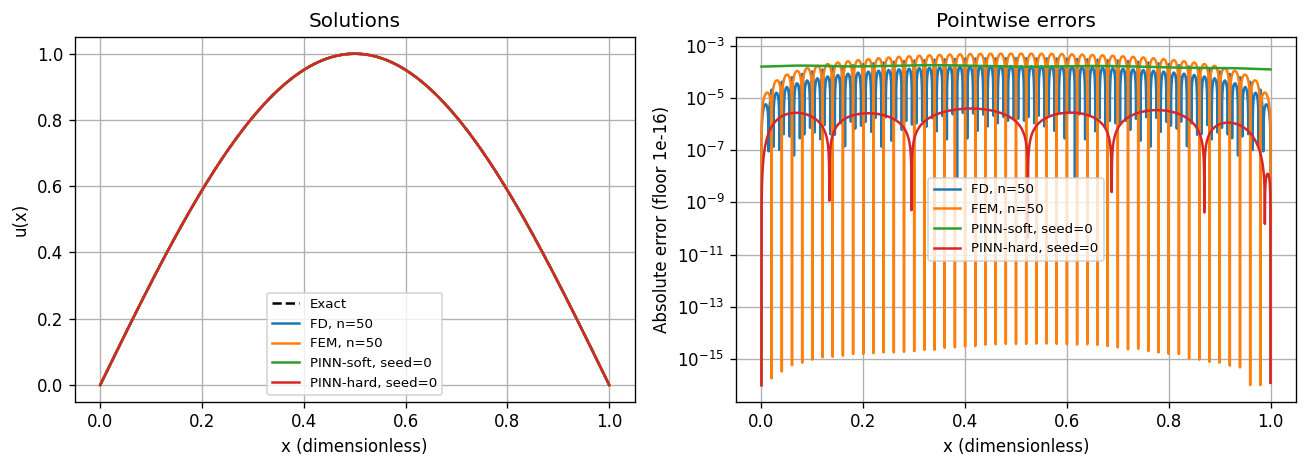

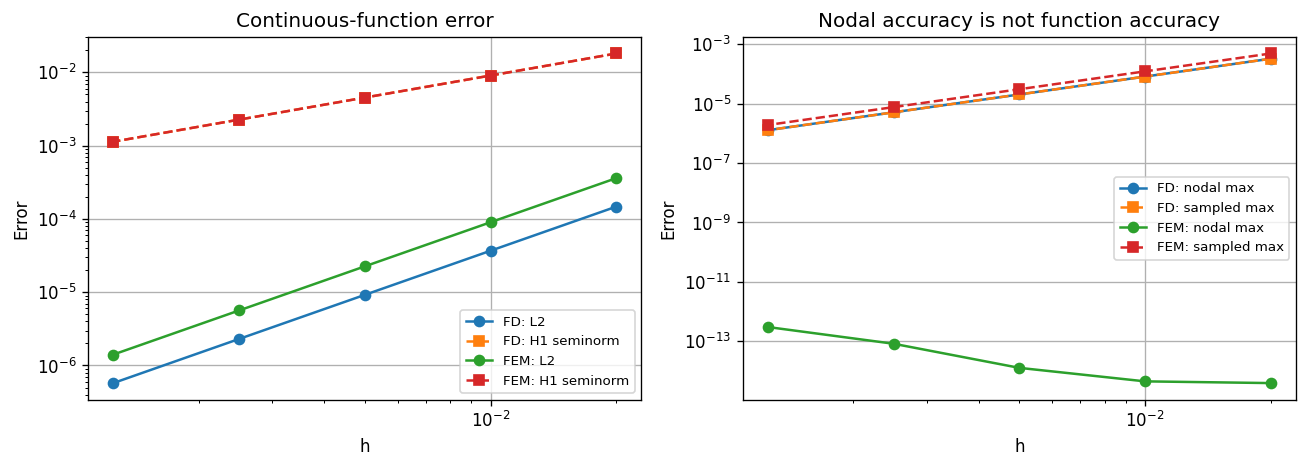

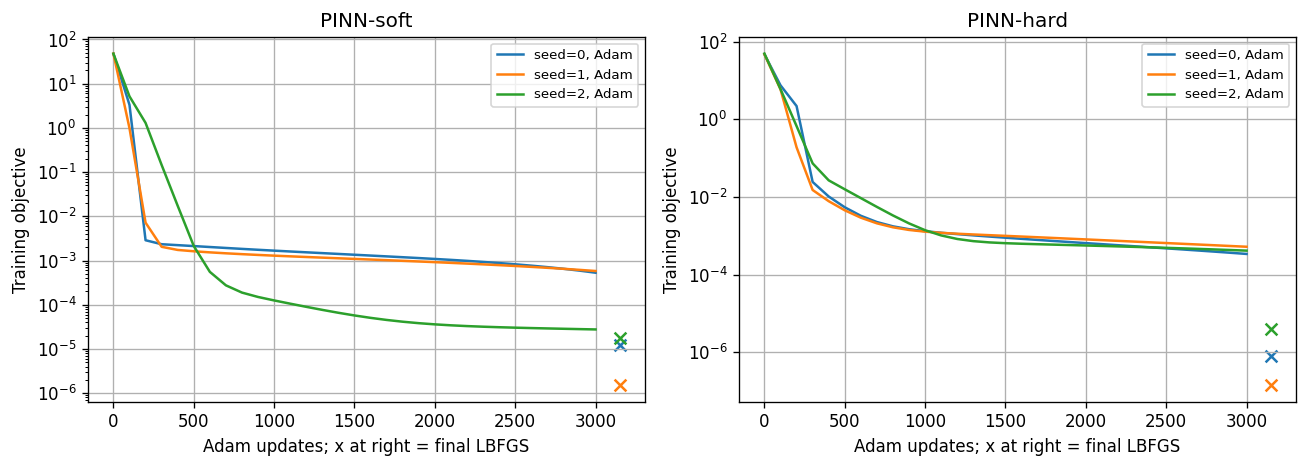

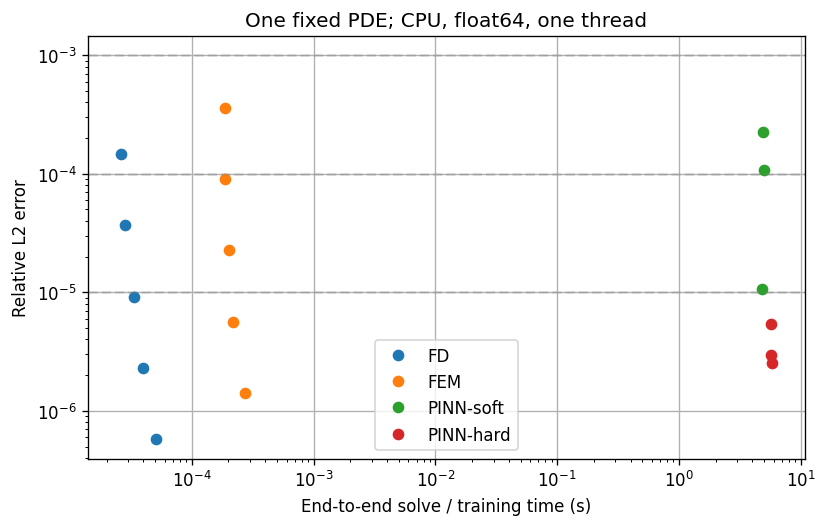

A部分已完成，接下来运行反问题和算子学习。


In [6]:
fig,axs=plt.subplots(1,2,figsize=(11,4))
axs[0].plot(XD,exact(XD),'k--',label='Exact')
for method in ['FD','FEM']:
    v=solutions[(method,50)][0](XD)
    axs[0].plot(XD,v,label=f'{method}, n=50')
    axs[1].semilogy(XD,np.maximum(abs(v-exact(XD)),1e-16),label=f'{method}, n=50')
for method in ['PINN-soft','PINN-hard']:
    v=network_functions(models[(method,0)])[0](XD)
    axs[0].plot(XD,v,label=f'{method}, seed=0')
    axs[1].semilogy(XD,np.maximum(abs(v-exact(XD)),1e-16),label=f'{method}, seed=0')
axs[0].set(xlabel='x (dimensionless)',ylabel='u(x)',title='Solutions')
axs[1].set(xlabel='x (dimensionless)',ylabel='Absolute error (floor 1e-16)',title='Pointwise errors')
for ax in axs: ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG/'A1组-6.4-正问题解与误差.png'); plt.show()

fig,axs=plt.subplots(1,2,figsize=(11,4))
for method in ['FD','FEM']:
    rows=[r for r in grid_rows if r['method']==method]
    ns=np.array([r['n'] for r in rows]); hs=1/ns
    axs[0].loglog(hs,[r['rel_l2'] for r in rows],'o-',label=f'{method}: L2')
    axs[0].loglog(hs,[r['rel_h1_semi'] for r in rows],'s--',label=f'{method}: H1 seminorm')
    axs[1].loglog(hs,[r['nodal_max'] for r in rows],'o-',label=f'{method}: nodal max')
    axs[1].loglog(hs,[r['max_sample'] for r in rows],'s--',label=f'{method}: sampled max')
for ax in axs: ax.set(xlabel='h',ylabel='Error'); ax.legend(fontsize=8)
axs[0].set_title('Continuous-function error'); axs[1].set_title('Nodal accuracy is not function accuracy')
fig.tight_layout(); fig.savefig(FIG/'A1组-6.4-网格收敛.png'); plt.show()

fig,axs=plt.subplots(1,2,figsize=(11,4))
for method,ax in zip(['PINN-soft','PINN-hard'],axs):
    for seed in [0,1,2]:
        hist=histories[f'{method}-{seed}']; adam=hist[:-1]
        line,=ax.semilogy([r['step'] for r in adam],[r['loss'] for r in adam],label=f'seed={seed}, Adam')
        ax.scatter([3150],[hist[-1]['loss']],marker='x',s=50,color=line.get_color())
    ax.set(xlabel='Adam updates; x at right = final LBFGS',ylabel='Training objective',title=method)
    ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG/'A1组-6.4-PINN训练曲线.png'); plt.show()

fig,ax=plt.subplots(figsize=(7,4.5))
for method in ['FD','FEM','PINN-soft','PINN-hard']:
    rows=[r for r in grid_rows+pinn_rows if r['method']==method]
    ax.loglog([r['solve_s'] for r in rows],[r['rel_l2'] for r in rows],'o',label=method)
for tol in [1e-3,1e-4,1e-5]: ax.axhline(tol,color='gray',alpha=.3,linestyle='--')
ax.set(xlabel='End-to-end solve / training time (s)',ylabel='Relative L2 error',title='One fixed PDE; CPU, float64, one thread')
ax.legend(); fig.tight_layout(); fig.savefig(FIG/'A1组-6.4-正问题成本.png'); plt.show()

save_csv(DATA/'A1组-6.4-网格结果.csv',grid_rows); save_csv(DATA/'A1组-6.4-PINN结果.csv',pinn_rows)
save_csv(DATA/'A1组-6.4-正问题阈值.csv',thresholds); save_csv(DATA/'A1组-6.4-积分检查.csv',quad_checks)
save_csv(DATA/'A1组-6.4-PINN汇总.csv',summary)
forward_payload=dict(environment=ENV,grid=grid_rows,pinn=pinn_rows,summary=summary,thresholds=thresholds,checks=checks,histories=histories)
(DATA/'A1组-6.4-正问题结果.json').write_text(json.dumps(forward_payload,ensure_ascii=False,indent=2),encoding='utf-8')
print('A部分已完成，接下来运行反问题和算子学习。')

## B. 6.2反问题：相同观测下的PINN、解析最小二乘和差分反演

沿用组员的E1—E5、种子2026—2030、Glorot初始化、256个含端点配点、软边界、Adam2000步及学习率0.01。
下面直接内嵌组员提供的NumPy网络、解析导数及反传实现，保留梯度检查；不调用外部脚本。
每次PINN和传统反演使用完全相同的观测数组。差分反演先解单位系数问题，再利用线性缩放进行一维最小二乘。
边界观测不可辨识时，传统基线返回空值并给出原因，不能悄悄使用真参数。
原组员耗时只作来源记录；本机PINN计时包括构建模型、训练与训练日志，不含精确解评价。

In [7]:
KAPPA_TRUE = 2.0
N_R = 256
N_EVAL = 1001
EPOCHS = 2000
LR = 0.01
SEEDS = [2026, 2027, 2028, 2029, 2030]

# 评价网格：单元中心，避开 x=0,1 与 0.01,...,0.05 等观测点
X_EVAL = (np.arange(N_EVAL) + 0.5) / N_EVAL

SETTINGS = [
    {
        "id": "E1",
        "name": "内部均匀, 无噪声",
        "x_d": np.array([1 / 6, 2 / 6, 3 / 6, 4 / 6, 5 / 6], dtype=float),
        "sigma": 0.0,
    },
    {
        "id": "E2",
        "name": "内部均匀, 有噪声",
        "x_d": np.array([1 / 6, 2 / 6, 3 / 6, 4 / 6, 5 / 6], dtype=float),
        "sigma": 0.005,
    },
    {
        "id": "E3",
        "name": "近边界, 无噪声",
        "x_d": np.array([0.01, 0.02, 0.03, 0.04, 0.05], dtype=float),
        "sigma": 0.0,
    },
    {
        "id": "E4",
        "name": "仅边界, 无噪声",
        "x_d": np.array([0.0, 1.0], dtype=float),
        "sigma": 0.0,
    },
    {
        "id": "E5",
        "name": "仅边界, 有噪声",
        "x_d": np.array([0.0, 1.0], dtype=float),
        "sigma": 0.005,
    },
]



class MLP:
    """1-32-32-1 tanh MLP，返回 u, u_x, u_xx。"""

    def __init__(self, seed: int, sizes=(1, 32, 32, 1)):
        rng = np.random.default_rng(seed)
        self.sizes = sizes
        self.W = []
        self.b = []
        for fan_in, fan_out in zip(sizes[:-1], sizes[1:]):
            limit = np.sqrt(6.0 / (fan_in + fan_out))  # Glorot uniform
            self.W.append(rng.uniform(-limit, limit, size=(fan_out, fan_in)))
            self.b.append(np.zeros(fan_out, dtype=float))

    def forward(self, x: np.ndarray):
        """x: (N,1). 返回 u,u_x,u_xx 与 cache。"""
        x = np.asarray(x, dtype=float).reshape(-1, 1)
        h = x
        h1 = np.ones_like(x)
        h2 = np.zeros_like(x)
        cache = []
        for i in range(len(self.W) - 1):
            W, b = self.W[i], self.b[i]
            z = h @ W.T + b
            z1 = h1 @ W.T
            z2 = h2 @ W.T
            a = np.tanh(z)
            s = 1.0 - a * a
            a1 = s * z1
            a2 = -2.0 * a * s * z1 * z1 + s * z2
            cache.append((h, h1, h2, z, a, s, z1, z2))
            h, h1, h2 = a, a1, a2
        Wo, bo = self.W[-1], self.b[-1]
        u = h @ Wo.T + bo
        u1 = h1 @ Wo.T
        u2 = h2 @ Wo.T
        cache.append((h, h1, h2, u, u1, u2))
        return u, u1, u2, cache

    def backward(self, cache, gu, gu1, gu2):
        """给定 loss 对 u,u_x,u_xx 的梯度，返回 dW,db。"""
        grads_W = [None] * len(self.W)
        grads_b = [None] * len(self.b)

        h, h1, h2, u, u1, u2 = cache[-1]
        Wo = self.W[-1]
        grads_W[-1] = gu.T @ h + gu1.T @ h1 + gu2.T @ h2
        # 输出层偏置只进入 u，不进入 u_x/u_xx
        grads_b[-1] = gu.sum(0)
        gh = gu @ Wo
        gh1 = gu1 @ Wo
        gh2 = gu2 @ Wo

        for i in range(len(self.W) - 2, -1, -1):
            h_prev, h1_prev, h2_prev, z, a, s, z1, z2 = cache[i]
            # a = tanh(z)
            # a1 = s*z1
            # a2 = -2*a*s*z1^2 + s*z2
            gz = (
                gh * s
                + gh1 * (-2.0 * a * s * z1)
                + gh2 * (-2.0 * s * (1.0 - 3.0 * a * a) * z1 * z1 - 2.0 * a * s * z2)
            )
            gz1 = gh1 * s + gh2 * (-4.0 * a * s * z1)
            gz2 = gh2 * s

            W = self.W[i]
            grads_W[i] = gz.T @ h_prev + gz1.T @ h1_prev + gz2.T @ h2_prev
            # 隐藏层偏置只进入 z，不进入 z_x/z_xx
            grads_b[i] = gz.sum(0)

            gh = gz @ W
            gh1 = gz1 @ W
            gh2 = gz2 @ W

        return grads_W, grads_b


def loss_and_grads(net: MLP, alpha: np.ndarray, x_r, x_b, x_d, y_d):
    """返回 loss, (dW,db,dalpha), 各项损失。"""
    kappa = float(np.exp(alpha[0]))

    # PDE residual
    u_r, u1_r, u2_r, cache_r = net.forward(x_r)
    f_r = np.pi**2 * np.sin(np.pi * x_r)
    r = -kappa * u2_r - f_r
    L_r = float(np.mean(r * r))
    gu_r = np.zeros_like(u_r)
    gu1_r = np.zeros_like(u_r)
    gu2_r = (2.0 / r.size) * r * (-kappa)
    dW_r, db_r = net.backward(cache_r, gu_r, gu1_r, gu2_r)
    dkappa = float(np.mean(2.0 * r * (-u2_r)))

    # boundary (soft)
    u_b, _, _, cache_b = net.forward(x_b)
    L_b = float(np.mean(u_b * u_b))
    gu_b = (2.0 / u_b.size) * u_b
    gu1_b = np.zeros_like(u_b)
    gu2_b = np.zeros_like(u_b)
    dW_b, db_b = net.backward(cache_b, gu_b, gu1_b, gu2_b)

    # data
    u_d, _, _, cache_d = net.forward(x_d)
    L_d = float(np.mean((u_d - y_d) ** 2))
    gu_d = (2.0 / u_d.size) * (u_d - y_d)
    gu1_d = np.zeros_like(u_d)
    gu2_d = np.zeros_like(u_d)
    dW_d, db_d = net.backward(cache_d, gu_d, gu1_d, gu2_d)

    dW = [a + b + c for a, b, c in zip(dW_r, dW_b, dW_d)]
    db = [a + b + c for a, b, c in zip(db_r, db_b, db_d)]
    dalpha = np.array([dkappa * kappa], dtype=float)
    loss = L_r + L_b + L_d
    return loss, (dW, db, dalpha), (L_r, L_b, L_d)


def total_loss(net: MLP, alpha, x_r, x_b, x_d, y_d) -> float:
    kappa = float(np.exp(alpha[0]))
    u_r, _, u2_r, _ = net.forward(x_r)
    f_r = np.pi**2 * np.sin(np.pi * x_r)
    L_r = float(np.mean((-kappa * u2_r - f_r) ** 2))
    u_b, _, _, _ = net.forward(x_b)
    L_b = float(np.mean(u_b * u_b))
    u_d, _, _, _ = net.forward(x_d)
    L_d = float(np.mean((u_d - y_d) ** 2))
    return L_r + L_b + L_d


def init_adam(params):
    m = [np.zeros_like(p, dtype=float) for p in params]
    v = [np.zeros_like(p, dtype=float) for p in params]
    return m, v


def adam_step(params, grads, m, v, t, lr=LR, beta1=0.9, beta2=0.999, eps=1e-8):
    for i in range(len(params)):
        g = grads[i]
        m[i] = beta1 * m[i] + (1.0 - beta1) * g
        v[i] = beta2 * v[i] + (1.0 - beta2) * (g * g)
        mhat = m[i] / (1.0 - beta1**t)
        vhat = v[i] / (1.0 - beta2**t)
        params[i] -= lr * mhat / (np.sqrt(vhat) + eps)


def make_data(setting, seed):
    rng = np.random.default_rng(seed)
    x_d = setting["x_d"].reshape(-1, 1)
    y_clean = np.sin(np.pi * x_d) / KAPPA_TRUE
    noise = setting["sigma"] * rng.normal(size=x_d.shape)
    y_d = y_clean + noise
    x_r = np.linspace(0.0, 1.0, N_R).reshape(-1, 1)
    x_b = np.array([[0.0], [1.0]])
    return x_r, x_b, x_d, y_d


def evaluate(net: MLP, alpha, x_d, y_d):
    kappa = float(np.exp(alpha[0]))
    # 主评价：单元中心网格（与观测点不重合）
    u, u1, u2, _ = net.forward(X_EVAL.reshape(-1, 1))
    u_true = np.sin(np.pi * X_EVAL) / KAPPA_TRUE
    rel_l2 = float(np.linalg.norm(u.ravel() - u_true) / np.linalg.norm(u_true))
    max_err = float(np.max(np.abs(u.ravel() - u_true)))
    residual = -kappa * u2.ravel() - np.pi**2 * np.sin(np.pi * X_EVAL)
    residual_rms = float(np.sqrt(np.mean(residual**2)))
    # 观测点与边界
    u_d, _, _, _ = net.forward(x_d)
    obs_rmse = float(np.sqrt(np.mean((u_d - y_d) ** 2)))
    u_b, _, _, _ = net.forward(np.array([[0.0], [1.0]]))
    boundary_err = float(np.max(np.abs(u_b)))
    return {
        "kappa_hat": kappa,
        "param_rel_err": abs(kappa - KAPPA_TRUE) / KAPPA_TRUE,
        "rel_l2": rel_l2,
        "max_err": max_err,
        "obs_rmse": obs_rmse,
        "residual_rms": residual_rms,
        "boundary_err": boundary_err,
    }


def run_one(setting, seed, epochs=EPOCHS, lr=LR, verbose=False):
    x_r, x_b, x_d, y_d = make_data(setting, seed)
    net = MLP(seed=seed)
    alpha = np.array([0.0], dtype=float)  # kappa0 = 1
    params = net.W + net.b + [alpha]
    m, v = init_adam(params)

    loss_hist = np.empty(epochs, dtype=float)
    kappa_hist = np.empty(epochs, dtype=float)
    Lr_hist = np.empty(epochs, dtype=float)
    Lb_hist = np.empty(epochs, dtype=float)
    Ld_hist = np.empty(epochs, dtype=float)

    t0 = time.perf_counter()
    for epoch in range(1, epochs + 1):
        loss, (dW, db, dalpha), (Lr, Lb, Ld) = loss_and_grads(
            net, alpha, x_r, x_b, x_d, y_d
        )
        grads = dW + db + [dalpha]
        adam_step(params, grads, m, v, epoch, lr=lr)
        loss_hist[epoch - 1] = loss
        kappa_hist[epoch - 1] = float(np.exp(alpha[0]))
        Lr_hist[epoch - 1] = Lr
        Lb_hist[epoch - 1] = Lb
        Ld_hist[epoch - 1] = Ld
        if verbose and (epoch == 1 or epoch % 200 == 0):
            print(
                f"{setting['id']} seed={seed} epoch={epoch:4d} "
                f"loss={loss:.4e} kappa={float(np.exp(alpha[0])):.6f} "
                f"Lr={Lr:.3e} Lb={Lb:.3e} Ld={Ld:.3e}"
            )
    elapsed = time.perf_counter() - t0

    metrics = evaluate(net, alpha, x_d, y_d)
    metrics.update(
        {
            "setting": setting["id"],
            "name": setting["name"],
            "seed": seed,
            "sigma": setting["sigma"],
            "n_d": int(len(setting["x_d"])),
            "epochs": epochs,
            "lr": lr,
            "time_s": elapsed,
            "final_loss": float(loss_hist[-1]),
            "Lr_final": float(Lr_hist[-1]),
            "Lb_final": float(Lb_hist[-1]),
            "Ld_final": float(Ld_hist[-1]),
        }
    )
    return metrics, {
        "loss": loss_hist,
        "kappa": kappa_hist,
        "Lr": Lr_hist,
        "Lb": Lb_hist,
        "Ld": Ld_hist,
    }, net, alpha, (x_r, x_b, x_d, y_d)


def gradient_check():
    """有限差分核验：u_xx、参数梯度、alpha 梯度。"""
    rng = np.random.default_rng(123)
    net = MLP(seed=999)
    alpha = np.array([np.log(1.7)])
    x_r = np.linspace(0.02, 0.98, 7).reshape(-1, 1)
    x_b = np.array([[0.0], [1.0]])
    x_d = np.array([[0.2], [0.4], [0.6]])
    y_d = np.sin(np.pi * x_d) / KAPPA_TRUE
    loss, (dW, db, dalpha), _ = loss_and_grads(net, alpha, x_r, x_b, x_d, y_d)
    params = net.W + net.b + [alpha]
    grads = dW + db + [dalpha]

    # u_xx 核验
    x0 = np.array([[0.37]])
    h = 1e-5
    u0, _, _, _ = net.forward(x0)
    up, _, _, _ = net.forward(x0 + h)
    um, _, _, _ = net.forward(x0 - h)
    u2_fd = (up - 2 * u0 + um) / h**2
    _, _, u2_an, _ = net.forward(x0)
    uxx_rel = abs(float(u2_an[0, 0] - u2_fd[0, 0])) / max(1.0, abs(float(u2_fd[0, 0])))

    # 参数梯度核验（抽 6 个参数）
    checks = []
    for _ in range(6):
        pi = int(rng.integers(0, len(params)))
        idx = tuple(int(rng.integers(0, s)) for s in params[pi].shape)
        eps = 1e-6
        old = params[pi][idx]
        params[pi][idx] = old + eps
        lp = total_loss(net, alpha, x_r, x_b, x_d, y_d)
        params[pi][idx] = old - eps
        lm = total_loss(net, alpha, x_r, x_b, x_d, y_d)
        params[pi][idx] = old
        fd = (lp - lm) / (2 * eps)
        an = float(grads[pi][idx])
        rel = abs(an - fd) / max(1e-8, abs(fd))
        checks.append((pi, idx, an, fd, rel))
    max_rel = max(c[4] for c in checks)
    print(f"gradient_check: uxx_rel={uxx_rel:.3e}, max_param_rel={max_rel:.3e}")
    for c in checks:
        print(f"  param[{c[0]}]{c[1]} analytic={c[2]:.6e} fd={c[3]:.6e} rel={c[4]:.2e}")
    return uxx_rel, max_rel



gcheck=gradient_check()
assert gcheck[0]<1e-4 and gcheck[1]<1e-3

gradient_check: uxx_rel=7.235e-07, max_param_rel=9.723e-08
  param[0](21, 0) analytic=1.302928e+00 fd=1.302928e+00 rel=1.08e-09
  param[4](1,) analytic=4.690593e-02 fd=4.690594e-02 rel=9.72e-08
  param[6](0,) analytic=-2.389420e+00 fd=-2.389420e+00 rel=1.56e-09
  param[1](8, 5) analytic=-1.763744e-01 fd=-1.763744e-01 rel=2.12e-08
  param[2](0, 5) analytic=-2.708831e-01 fd=-2.708831e-01 rel=1.91e-08
  param[2](0, 25) analytic=-2.092641e-01 fd=-2.092642e-01 rel=4.68e-08


E1 seed=2026: PINN kappa=1.842652, parameter error=7.867%, time=1.98s


E1 seed=2027: PINN kappa=1.859131, parameter error=7.043%, time=1.99s


E1 seed=2028: PINN kappa=1.868230, parameter error=6.588%, time=1.97s


E1 seed=2029: PINN kappa=1.890700, parameter error=5.465%, time=2.02s


E1 seed=2030: PINN kappa=1.850027, parameter error=7.499%, time=1.93s


...

E5 seed=2027: PINN kappa=1.387056, parameter error=30.647%, time=1.90s


E5 seed=2028: PINN kappa=1.336366, parameter error=33.182%, time=1.94s


E5 seed=2029: PINN kappa=1.372980, parameter error=31.351%, time=1.95s


E5 seed=2030: PINN kappa=1.326400, parameter error=33.680%, time=1.97s


| setting | method | status | param_rel_err_mean | rel_l2_mean | time_mean_s |
| --- | --- | --- | --- | --- | --- |
| E1 | Analytic-LS | identified | 0.000000e+00 | 0.000000e+00 | 2.240000e-05 |
| E1 | FD-LS | identified | 5.711683e-07 | 2.368813e-06 | 1.044200e-04 |
| E1 | PINN-inverse | identified | 6.892606e-02 | 5.142345e-02 | 1.976540e+00 |
| E2 | Analytic-LS | identified | 4.885298e-03 | 4.864426e-03 | 2.094000e-05 |
| E2 | FD-LS | identified | 4.885413e-03 | 4.864537e-03 | 1.219200e-04 |
| E2 | PINN-inverse | identified | 6.329395e-02 | 4.030680e-02 | 1.992632e+00 |
| E3 | Analytic-LS | identified | 0.000000e+00 | 0.000000e+00 | 2.578000e-05 |
| E3 | FD-LS | identified | 5.140435e-06 | 5.631039e-06 | 1.215600e-04 |
| E3 | PINN-inverse | identified | 3.168948e-01 | 4.482040e-01 | 1.989416e+00 |
| E4 | Analytic-LS | unidentifiable | None | None | 3.570000e-05 |
| E4 | FD-LS | unidentifiable | None | None | 1.170000e-04 |
| E4 | PINN-inverse | unidentifiable | 3.302261e-01 | 4.886257e-01 | 1.938824e+00 |
| E5 | Analytic-LS | unidentifiable | None | None | 3.836000e-05 |
| E5 | FD-LS | unidentifiable | None | None | 1.477200e-04 |
| E5 | PINN-inverse | unidentifiable | 3.312086e-01 | 5.011194e-01 | 1.928288e+00 |

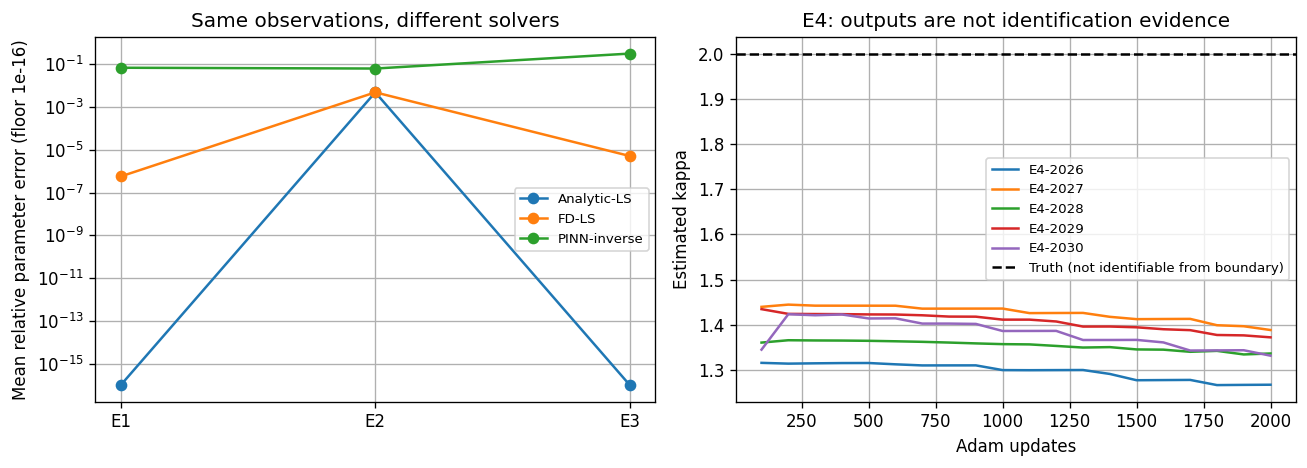

In [8]:
def inverse_fit(xd,yd,method,n=400):
    solve_start=time.perf_counter()
    xd=np.asarray(xd).ravel(); yd=np.asarray(yd).ravel()
    if method=='Analytic-LS':
        q=np.sin(np.pi*xd); q[(xd==0)|(xd==1)]=0
        val=lambda x:np.sin(np.pi*x)
    else:
        gx,gu=fd(n); q=np.interp(xd,gx,gu); val=lambda x:np.interp(x,gx,gu)
    denom=float(q@q)
    if denom<=1e-24:
        return dict(kappa_hat=None,param_rel_err=None,rel_l2=None,obs_rmse=float(np.sqrt(np.mean(yd**2))),status='unidentifiable',time_s=time.perf_counter()-solve_start)
    a=float(q@yd/denom)
    if a<=0:
        return dict(kappa_hat=None,param_rel_err=None,rel_l2=None,obs_rmse=None,status='no_positive_finite_estimate',time_s=time.perf_counter()-solve_start)
    kappa=1/a; solve_s=time.perf_counter()-solve_start; truth=np.sin(np.pi*X_EVAL)/KAPPA_TRUE
    return dict(kappa_hat=kappa,param_rel_err=abs(kappa-KAPPA_TRUE)/KAPPA_TRUE,
        rel_l2=float(np.linalg.norm(a*val(X_EVAL)-truth)/np.linalg.norm(truth)),
        obs_rmse=float(np.sqrt(np.mean((a*q-yd)**2))),status='identified',time_s=solve_s)

inverse_rows=[]; obs_rows=[]; inv_history={}
for setting in SETTINGS:
    for seed in SEEDS:
        xr,xb,xd,yd=make_data(setting,seed)
        obs_rows.extend(dict(setting=setting['id'],seed=seed,x=float(x),y=float(y)) for x,y in zip(xd.ravel(),yd.ravel()))
        for method in ['Analytic-LS','FD-LS']:
            fit=inverse_fit(xd,yd,method)
            inverse_rows.append(dict(setting=setting['id'],seed=seed,method=method,**fit))
        # Time includes model/Adam construction but excludes evaluation, same data as both baselines.
        start=time.perf_counter(); net=MLP(seed); alpha=np.array([0.]); params=net.W+net.b+[alpha]; mom,var=init_adam(params)
        h=[]
        for step in range(1,EPOCHS+1):
            loss,(dw,db,da),parts=loss_and_grads(net,alpha,xr,xb,xd,yd)
            adam_step(params,dw+db+[da],mom,var,step,lr=LR)
            if step%100==0:h.append([step,float(np.exp(alpha[0]))])
        elapsed=time.perf_counter()-start
        fit=evaluate(net,alpha,xd,yd)
        inverse_rows.append(dict(setting=setting['id'],seed=seed,method='PINN-inverse',**fit,time_s=elapsed,
            status='unidentifiable' if setting['id'] in ['E4','E5'] else 'identified'))
        inv_history[f"{setting['id']}-{seed}"]=h
        print(f"{setting['id']} seed={seed}: PINN kappa={fit['kappa_hat']:.6f}, parameter error={fit['param_rel_err']:.3%}, time={elapsed:.2f}s",flush=True)

inverse_summary=[]
for case in ['E1','E2','E3','E4','E5']:
    for method in ['Analytic-LS','FD-LS','PINN-inverse']:
        rows=[r for r in inverse_rows if r['setting']==case and r['method']==method]
        row=dict(setting=case,method=method,status=rows[0]['status'],seeds=len(rows),time_mean_s=float(np.mean([r['time_s'] for r in rows])))
        for key in ['param_rel_err','rel_l2','kappa_hat','obs_rmse']:
            vals=[r[key] for r in rows if r[key] is not None]
            row[key+'_mean']=float(np.mean(vals)) if vals else None
            row[key+'_sd']=float(np.std(vals,ddof=1)) if len(vals)>1 else None
        inverse_summary.append(row)
table(inverse_summary,['setting','method','status','param_rel_err_mean','rel_l2_mean','time_mean_s'])
assert all(r['kappa_hat'] is None for r in inverse_rows if r['method']!='PINN-inverse' and r['setting'] in ['E4','E5'])
assert max(r['param_rel_err'] for r in inverse_rows if r['method']=='Analytic-LS' and r['setting'] in ['E1','E3'])<1e-12
save_csv(DATA/'A1组-6.4-反问题逐次结果.csv',inverse_rows)
save_csv(DATA/'A1组-6.4-反问题汇总.csv',inverse_summary)
save_csv(DATA/'A1组-6.4-反问题共同观测.csv',obs_rows)
fig,axes=plt.subplots(1,2,figsize=(11,4))
for method in ['Analytic-LS','FD-LS','PINN-inverse']:
    rows=[r for r in inverse_summary if r['method']==method and r['setting'] in ['E1','E2','E3']]
    axes[0].semilogy([r['setting'] for r in rows],np.maximum([r['param_rel_err_mean'] for r in rows],1e-16),'o-',label=method)
for key,h in inv_history.items():
    if key.startswith('E4'):axes[1].plot(np.array(h)[:,0],np.array(h)[:,1],label=key)
axes[1].axhline(2,color='black',ls='--',label='Truth (not identifiable from boundary)')
axes[0].set(ylabel='Mean relative parameter error (floor 1e-16)',title='Same observations, different solvers')
axes[1].set(xlabel='Adam updates',ylabel='Estimated kappa',title='E4: outputs are not identification evidence')
for a in axes:a.legend(fontsize=8)
fig.tight_layout();fig.savefig(FIG/'A1组-6.4-反问题对照.png');plt.show()

## C. 6.3算子学习：Python 3.12同机重跑，而非搬运MATLAB耗时

使用组员交付的1800个输入函数的实际Fourier系数，保持1000/200/200/200/200的函数级划分。
方程为周期问题 $-w''+w=f$；不是A/B部分的零Dirichlet Poisson问题。
DeepONet: branch 32-64-64-32、trunk 1-64-64-32，tanh，输出加标量偏置；共14721参数。
Adam lr=0.001、batch=32、最多1000 epoch、验证均值patience=100、种子2024。
使用CPU float64和Glorot初始化；每轮包括最后8个训练函数（原MATLAB实现丢弃不足32的最后一批）。这是明确标注的Python改编，不要求复刻原MATLAB参数轨迹。

传统方法和网络都只收到同样的32个源项传感器值。利用已声明带宽K≤8<16，用三角插值到64点；
谱求解器用连续算子的频率符号，差分求解器用周期二阶差分矩阵的特征值，以FFT实现循环矩阵求解。
测试真值另用解析系数计算；原MATLAB预测不参与本次训练或选模。

In [9]:
import copy
with open(DATA/'A1组-6.4-来源63-deeponet_dataset_coefficients.csv',encoding='utf-8-sig',newline='') as fh:
    coefficient_rows=list(csv.DictReader(fh))
def evaluate_coeff(rows,x,solution=False):
    x=np.asarray(x); out=np.stack([np.full_like(x,float(r['a0']),dtype=float) for r in rows])
    for k in range(1,9):
        a=np.array([float(r['a'+str(k)]) if r['a'+str(k)] else 0. for r in rows])
        b=np.array([float(r['b'+str(k)]) if r['b'+str(k)] else 0. for r in rows])
        out+=(a[:,None]*np.cos(2*np.pi*k*x)+b[:,None]*np.sin(2*np.pi*k*x))/(1+(2*np.pi*k)**2 if solution else 1)
    return out
YS=np.arange(32)/32; YG=np.arange(64)/64; KF=np.fft.rfftfreq(64,d=1/64)
def source32_to64(samples):
    coef=np.fft.rfft(samples,axis=-1); padded=np.zeros((*coef.shape[:-1],33),complex)
    padded[...,:16]=coef[...,:16];padded[...,16]=coef[...,16]/2
    return np.fft.irfft(padded,n=64,axis=-1)*2
def op_solve(samples,method='spectral'):
    f64=source32_to64(samples)
    lam=1+(2*np.pi*KF)**2 if method=='spectral' else 1+4*64**2*np.sin(np.pi*KF/64)**2
    return np.fft.irfft(np.fft.rfft(f64,axis=-1)/lam,n=64,axis=-1)

op_data={}; gen_start=time.perf_counter()
for split in ['train','validation','test','ood_amplitude','ood_frequency']:
    rows=[r for r in coefficient_rows if r['split']==split]
    sensors=evaluate_coeff(rows,YS); labels=op_solve(sensors)
    truth=evaluate_coeff(rows,YG,True)
    assert np.max(abs(labels-truth))<1e-12
    op_data[split]=dict(rows=rows,sensors=sensors,labels=labels,truth=truth)
data_generation_s=time.perf_counter()-gen_start
ids=[tuple(float(r[k]) if r[k] else 0. for k in ['a0']+[f'a{i}' for i in range(1,9)]+[f'b{i}' for i in range(1,9)]) for r in coefficient_rows]
assert len(set(ids))==len(ids)==1800
assert [len(op_data[k]['rows']) for k in op_data]==[1000,200,200,200,200]

class DeepOperator(torch.nn.Module):
    def __init__(self):
        super().__init__()
        def mlp(n):return torch.nn.Sequential(torch.nn.Linear(n,64),torch.nn.Tanh(),torch.nn.Linear(64,64),torch.nn.Tanh(),torch.nn.Linear(64,32))
        self.branch=mlp(32);self.trunk=mlp(1);self.bias=torch.nn.Parameter(torch.zeros(()))
        for m in self.modules():
            if isinstance(m,torch.nn.Linear):torch.nn.init.xavier_uniform_(m.weight);torch.nn.init.zeros_(m.bias)
    def forward(self,sensors,y):return self.branch(sensors)@self.trunk(y).T+self.bias

torch.manual_seed(2024);model_op=DeepOperator();assert sum(p.numel() for p in model_op.parameters())==14721
opti=torch.optim.Adam(model_op.parameters(),lr=1e-3)
TX=torch.tensor(op_data['train']['sensors']);TY=torch.tensor(op_data['train']['labels']);QY=torch.tensor(YG[:,None])
VX=torch.tensor(op_data['validation']['sensors']);VY=torch.tensor(op_data['validation']['labels'])
best=float('inf');best_state=None;best_epoch=0;stale=0;op_history=[];start=time.perf_counter()
for epoch in range(1,1001):
    perm=torch.randperm(len(TX));total=0.
    for start_i in range(0,len(TX),32):
        ix=perm[start_i:start_i+32];opti.zero_grad(set_to_none=True)
        loss=((model_op(TX[ix],QY)-TY[ix])**2).mean();loss.backward();opti.step();total+=float(loss.detach())*len(ix)
    with torch.no_grad():vl=float((torch.linalg.vector_norm(model_op(VX,QY)-VY,dim=1)/torch.linalg.vector_norm(VY,dim=1)).mean())
    op_history.append(dict(epoch=epoch,train_mse=total/len(TX),validation_mean_l2=vl))
    if vl<best:
        best=vl;best_epoch=epoch;best_state=copy.deepcopy(model_op.state_dict());stale=0
    else:stale+=1
    if epoch%100==0:print(f'DeepONet epoch={epoch}, validation={vl:.5e}, elapsed={time.perf_counter()-start:.1f}s',flush=True)
    if stale>=100:break
op_train_s=time.perf_counter()-start;model_op.load_state_dict(best_state);model_op.eval()
print('Best epoch:',best_epoch,'epochs run:',epoch,'training seconds:',op_train_s)

DeepONet epoch=100, validation=4.01458e-02, elapsed=3.9s


DeepONet epoch=200, validation=2.31644e-02, elapsed=7.9s


DeepONet epoch=300, validation=2.05117e-02, elapsed=11.8s


DeepONet epoch=400, validation=1.02510e-02, elapsed=15.8s


DeepONet epoch=500, validation=6.11448e-03, elapsed=19.7s


DeepONet epoch=600, validation=8.07774e-03, elapsed=23.5s


DeepONet epoch=700, validation=5.13773e-03, elapsed=27.4s


Best epoch: 648 epochs run: 748 training seconds: 29.29527059999964


| split | method | mean_l2 | median_l2 | p95_l2 | mean_h1_full |
| --- | --- | --- | --- | --- | --- |
| test | DeepONet | 4.379071e-03 | 4.006193e-03 | 8.065477e-03 | 9.706236e-02 |
| test | Spectral-32 | 1.480201e-16 | 1.177384e-16 | 3.123912e-16 | 1.086722e-14 |
| test | FD-32-to-64 | 2.924958e-05 | 2.746641e-05 | 5.391465e-05 | 3.115496e-04 |
| test | Nearest-function | 1.661378e-01 | 1.297669e-01 | 4.601511e-01 | 1.767424e-01 |
| ood_amplitude | DeepONet | 8.740351e-03 | 8.083733e-03 | 1.530362e-02 | 1.522374e-01 |
| ood_amplitude | Spectral-32 | 2.010142e-16 | 1.769613e-16 | 4.543983e-16 | 1.047745e-14 |
| ood_amplitude | FD-32-to-64 | 4.788740e-05 | 4.469440e-05 | 8.062815e-05 | 5.030603e-04 |
| ood_frequency | DeepONet | 1.631443e-01 | 1.270718e-01 | 4.324917e-01 | 3.521580e-01 |
| ood_frequency | Spectral-32 | 2.276916e-16 | 2.034674e-16 | 4.404487e-16 | 1.624250e-14 |
| ood_frequency | FD-32-to-64 | 3.191093e-05 | 2.895258e-05 | 5.571679e-05 | 4.653065e-04 |

New-coordinate mean relative L2: 0.004364489173800185


| method | batch_functions | per_function_s |
| --- | --- | --- |
| Spectral-32 | 1 | 3.452600e-05 |
| FD-32-to-64 | 1 | 3.830600e-05 |
| DeepONet | 1 | 1.436010e-04 |
| Spectral-32 | 200 | 1.084150e-06 |
| FD-32-to-64 | 200 | 1.135750e-06 |
| DeepONet | 200 | 1.310150e-06 |
| Spectral-reused | 1 | 1.748000e-05 |
| FD-reused | 1 | 1.625900e-05 |
| Spectral-reused | 200 | 5.898000e-07 |
| FD-reused | 200 | 6.056000e-07 |
| DeepONet-cached-trunk | 1 | 6.533900e-05 |
| DeepONet-cached-trunk | 200 | 8.883500e-07 |

| network | solver | batch_functions | quality_p95_1pct | denominator_s | break_even_functions | reason |
| --- | --- | --- | --- | --- | --- | --- |
| DeepONet | Spectral-32 | 1 | True | -1.090750e-04 | None | no_positive_cost_denominator |
| DeepONet | FD-32-to-64 | 1 | True | -1.052950e-04 | None | no_positive_cost_denominator |
| DeepONet-cached-trunk | Spectral-reused | 1 | True | -4.785900e-05 | None | no_positive_cost_denominator |
| DeepONet-cached-trunk | FD-reused | 1 | True | -4.908000e-05 | None | no_positive_cost_denominator |
| DeepONet | Spectral-32 | 200 | True | -2.260000e-07 | None | no_positive_cost_denominator |
| DeepONet | FD-32-to-64 | 200 | True | -1.744000e-07 | None | no_positive_cost_denominator |
| DeepONet-cached-trunk | Spectral-reused | 200 | True | -2.985500e-07 | None | no_positive_cost_denominator |
| DeepONet-cached-trunk | FD-reused | 200 | True | -2.827500e-07 | None | no_positive_cost_denominator |

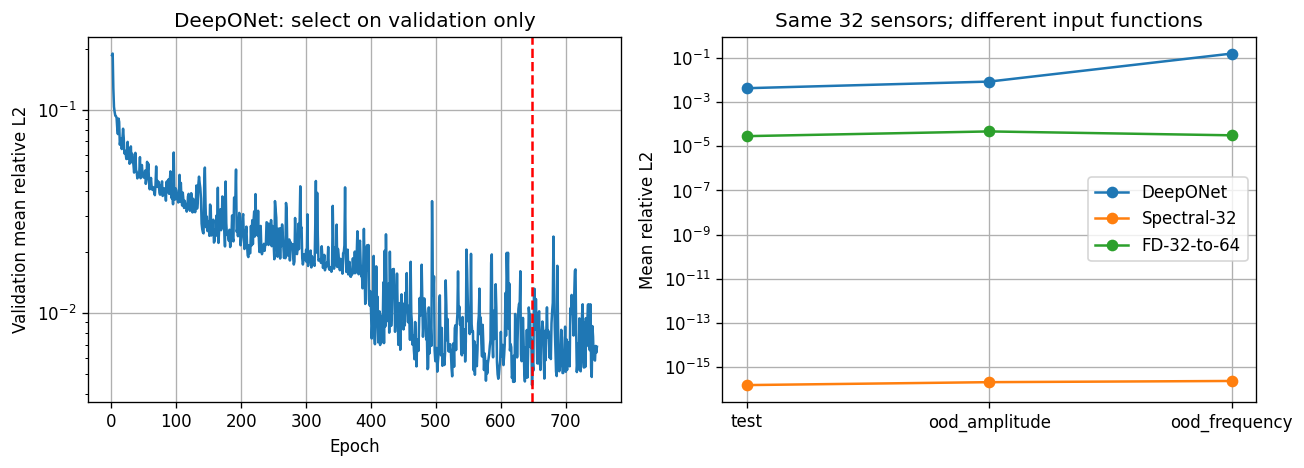

所有实测完成。FNO仅结构介绍，没有生成FNO性能数字。


In [10]:
def op_prediction(samples,y=YG):
    with torch.no_grad():return model_op(torch.tensor(samples),torch.tensor(np.asarray(y)[:,None])).numpy()
def rel_function(pred,truth):return np.linalg.norm(pred-truth,axis=1)/np.linalg.norm(truth,axis=1)
def op_h1(pred,truth):
    freq=np.fft.fftfreq(64,d=1/64)
    def deriv(a):return np.fft.ifft(np.fft.fft(a,axis=1)*(2j*np.pi*freq),axis=1).real
    return np.sqrt((np.sum((pred-truth)**2,axis=1)+np.sum((deriv(pred)-deriv(truth))**2,axis=1))/(np.sum(truth**2,axis=1)+np.sum(deriv(truth)**2,axis=1)))
op_rows=[]; op_per_function=[];predictions={}
for split in ['test','ood_amplitude','ood_frequency']:
    d=op_data[split]; truths=d['truth']
    predset={'DeepONet':op_prediction(d['sensors']),'Spectral-32':op_solve(d['sensors']),'FD-32-to-64':op_solve(d['sensors'],'fd')}
    if split=='test':
        dist=np.sum((d['sensors'][:,None,:]-op_data['train']['sensors'][None,:,:])**2,axis=2)
        predset['Nearest-function']=op_data['train']['labels'][np.argmin(dist,axis=1)]
    for method,pred in predset.items():
        e=rel_function(pred,truths);h=op_h1(pred,truths)
        op_rows.append(dict(split=split,method=method,mean_l2=float(e.mean()),median_l2=float(np.median(e)),p95_l2=float(np.quantile(e,.95)),max_l2=float(e.max()),mean_h1_full=float(h.mean())))
        op_per_function.extend(dict(split=split,method=method,function_id=i+1,rel_l2=float(v)) for i,v in enumerate(e))
        predictions[(split,method)]=pred
# New coordinates for the same new input functions: no training or selection uses these values.
rngq=np.random.default_rng(2064);yr=rngq.random((200,16));random_errors=[]
for i,row in enumerate(op_data['test']['rows']):
    truth=evaluate_coeff([row],yr[i],True);pred=op_prediction(op_data['test']['sensors'][i:i+1],yr[i]);random_errors.append(float(rel_function(pred,truth)[0]))
table(op_rows,['split','method','mean_l2','median_l2','p95_l2','mean_h1_full'])
print('New-coordinate mean relative L2:',np.mean(random_errors))

def time_average(fn, repeats):
    fn(); batches=[]
    for _ in range(7):
        start=time.perf_counter()
        for _ in range(repeats):fn()
        batches.append((time.perf_counter()-start)/repeats)
    return float(np.median(batches))
cost_rows=[]
for batch in [1,200]:
    samples=op_data['test']['sensors'][:batch]
    for method,fun in [('Spectral-32',lambda:op_solve(samples)),('FD-32-to-64',lambda:op_solve(samples,'fd')),('DeepONet',lambda:op_prediction(samples))]:
        t=time_average(fun,100 if batch==1 else 10)
        cost_rows.append(dict(method=method,batch_functions=batch,batch_s=t,per_function_s=t/batch))
# Reuse fixed frequency symbols, and remove a redundant inverse/forward FFT pair.
# This gives the traditional solvers the same opportunity to reuse fixed preparation.
cache_start=time.perf_counter()
cached_symbols={'spectral':1+(2*np.pi*KF)**2,'fd':1+4*64**2*np.sin(np.pi*KF/64)**2}
solver_prepare_s=time.perf_counter()-cache_start
def cached_solver(samples,method='spectral'):
    coef=np.fft.rfft(samples,axis=-1)
    padded=np.zeros((*coef.shape[:-1],33),complex)
    padded[...,:16]=coef[...,:16];padded[...,16]=coef[...,16]/2
    return np.fft.irfft(padded/cached_symbols[method],n=64,axis=-1)*2
for method in ['spectral','fd']:
    assert np.max(abs(cached_solver(op_data['test']['sensors'],method)-op_solve(op_data['test']['sensors'],method)))<1e-12
for batch in [1,200]:
    samples=op_data['test']['sensors'][:batch]
    for label,method in [('Spectral-reused','spectral'),('FD-reused','fd')]:
        t=time_average(lambda:cached_solver(samples,method),100 if batch==1 else 10)
        cost_rows.append(dict(method=label,batch_functions=batch,batch_s=t,per_function_s=t/batch))
# Reusable fixed query coordinates: distinguish cached tensor/trunk inference from end-to-end inference.
cache_start=time.perf_counter()
with torch.no_grad():cached_trunk=model_op.trunk(QY).T
net_prepare_s=time.perf_counter()-cache_start
def cached_net(s):
    with torch.no_grad():return (model_op.branch(torch.tensor(s))@cached_trunk+model_op.bias).numpy()
for batch in [1,200]:
    samples=op_data['test']['sensors'][:batch]; t=time_average(lambda:cached_net(samples),100 if batch==1 else 10)
    cost_rows.append(dict(method='DeepONet-cached-trunk',batch_functions=batch,batch_s=t,per_function_s=t/batch))
table(cost_rows,['method','batch_functions','per_function_s'])
amortization=[]
for batch in [1,200]:
    for network,solvers in [('DeepONet',['Spectral-32','FD-32-to-64']),('DeepONet-cached-trunk',['Spectral-reused','FD-reused'])]:
        net_t=next(r['per_function_s'] for r in cost_rows if r['method']==network and r['batch_functions']==batch)
        quality=next(r for r in op_rows if r['method']=='DeepONet' and r['split']=='test')['p95_l2']<=1e-2
        for solver in solvers:
            st=next(r['per_function_s'] for r in cost_rows if r['method']==solver and r['batch_functions']==batch)
            reference={'Spectral-reused':'Spectral-32','FD-reused':'FD-32-to-64'}.get(solver,solver)
            good=quality and next(r for r in op_rows if r['method']==reference and r['split']=='test')['p95_l2']<=1e-2
            offline=data_generation_s+op_train_s+(net_prepare_s-solver_prepare_s if network.endswith('trunk') else 0)
            amortization.append(dict(network=network,solver=solver,batch_functions=batch,denominator_s=st-net_t,quality_p95_1pct=good,
                break_even_functions=float(offline/(st-net_t)) if good and st>net_t else None,
                reason='available' if good and st>net_t else ('no_positive_cost_denominator' if st<=net_t else 'quality_threshold_not_met')))
table(amortization,['network','solver','batch_functions','quality_p95_1pct','denominator_s','break_even_functions','reason'])
save_csv(DATA/'A1组-6.4-算子误差汇总.csv',op_rows);save_csv(DATA/'A1组-6.4-算子逐函数误差.csv',op_per_function)
save_csv(DATA/'A1组-6.4-算子训练历史.csv',op_history);save_csv(DATA/'A1组-6.4-算子成本.csv',cost_rows)
save_csv(DATA/'A1组-6.4-算子摊销.csv',amortization)
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].semilogy([r['epoch'] for r in op_history],[r['validation_mean_l2'] for r in op_history]);axes[0].axvline(best_epoch,ls='--',color='red')
axes[0].set(xlabel='Epoch',ylabel='Validation mean relative L2',title='DeepONet: select on validation only')
for method in ['DeepONet','Spectral-32','FD-32-to-64']:
    rows=[r for r in op_rows if r['method']==method];axes[1].semilogy([r['split'] for r in rows],[r['mean_l2'] for r in rows],'o-',label=method)
axes[1].set(ylabel='Mean relative L2',title='Same 32 sensors; different input functions');axes[1].legend()
fig.tight_layout();fig.savefig(FIG/'A1组-6.4-算子学习对照.png');plt.show()

combined=dict(environment=ENV,forward=forward_payload,inverse=dict(rows=inverse_rows,summary=inverse_summary,gradient_check=gcheck),
    operator=dict(rows=op_rows,cost=cost_rows,amortization=amortization,train_s=op_train_s,data_generation_s=data_generation_s,
                  net_prepare_s=net_prepare_s,solver_prepare_s=solver_prepare_s,
                  best_epoch=best_epoch,epochs_run=epoch,seed=2024,random_coordinate_mean_l2=float(np.mean(random_errors))))
(DATA/'A1组-6.4-综合结果.json').write_text(json.dumps(combined,ensure_ascii=False,indent=2),encoding='utf-8')
print('所有实测完成。FNO仅结构介绍，没有生成FNO性能数字。')

## 结论边界与重跑说明

本Notebook分三种任务报告，不跨方程混排精度。反问题比较以同一观测数组为前提；不可辨识时不输出假识别结果。
算子学习使用同一输入系数与同样32个传感器信息；成本区分单次、200函数批量、固定trunk缓存。
算子部分H1指标为64点周期谱微分下的完整H1范数，不等同于A部分的导数半范数，也不保证非周期网络输出的真实连续H1精度。
网络是否准确、是否存在成本摊销点，均以保存输出为准。学习方法的低误差不能作为全部PDE或分布外性能的证明。
所有路径相对“工作”；目录已随包提供，代码中没有创建文件夹的语句。无需MATLAB、外部py或网络访问。